In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Use dark background theme
plt.style.use('dark_background')

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
data = load_breast_cancer()

print("="*80)
print("BREAST CANCER WISCONSIN DATASET")
print("="*80)
print(f"Number of samples: {data.data.shape[0]}")
print(f"Number of features: {data.data.shape[1]}")
print(f"\nClasses: {data.target_names}")
print(f"  - 0 = Malignant (cancerous)")
print(f"  - 1 = Benign (non-cancerous)")
print(f"\nClass distribution:")
unique, counts = np.unique(data.target, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  {data.target_names[label]}: {count} samples ({count/len(data.target)*100:.1f}%)")
print("="*80)

BREAST CANCER WISCONSIN DATASET
Number of samples: 569
Number of features: 30

Classes: ['malignant' 'benign']
  - 0 = Malignant (cancerous)
  - 1 = Benign (non-cancerous)

Class distribution:
  malignant: 212 samples (37.3%)
  benign: 357 samples (62.7%)


In [ ]:
print("\nAll 30 Features:")
print("="*80)
for i, feature_name in enumerate(data.feature_names, 1):
    print(f"{i:2d}. {feature_name}")
print("="*80)


All 30 Features:
 1. mean radius
 2. mean texture
 3. mean perimeter
 4. mean area
 5. mean smoothness
 6. mean compactness
 7. mean concavity
 8. mean concave points
 9. mean symmetry
10. mean fractal dimension
11. radius error
12. texture error
13. perimeter error
14. area error
15. smoothness error
16. compactness error
17. concavity error
18. concave points error
19. symmetry error
20. fractal dimension error
21. worst radius
22. worst texture
23. worst perimeter
24. worst area
25. worst smoothness
26. worst compactness
27. worst concavity
28. worst concave points
29. worst symmetry
30. worst fractal dimension


In [4]:
feature_indices = [0,1]
X = data.data[:, feature_indices]
y = data.target

print(f"Selected features:")
print(f"  Feature 1: {data.feature_names[feature_indices[0]]}")
print(f"  Feature 2: {data.feature_names[feature_indices[1]]}")
print(f"\nData shape: {X.shape}")
print(f"Labels shape: {y.shape}")


Selected features:
  Feature 1: mean radius
  Feature 2: mean texture

Data shape: (569, 2)
Labels shape: (569,)


/tmp/ipykernel_5520/1795474700.py:5: UserWarning: You passed a edgecolor/edgecolors ('white') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X[malignant_mask, 0], X[malignant_mask, 1],


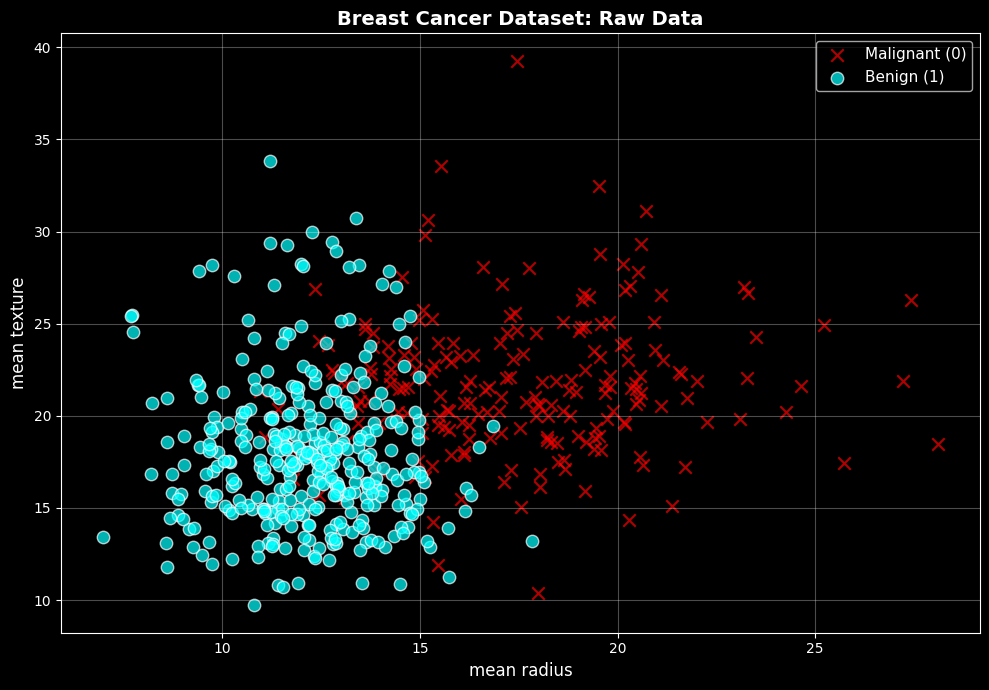

In [6]:
plt.figure(figsize=(10, 7), dpi=100)

malignant_mask = y == 0

plt.scatter(X[malignant_mask, 0], X[malignant_mask, 1],
            c='red', s=80, marker='x', label='Malignant (0)',
            edgecolors='white', linewidth=1.5, alpha=0.7)


benign_mask = y == 1
plt.scatter(X[benign_mask, 0], X[benign_mask, 1],
            c = 'cyan', s=80, marker='o', label= 'Benign (1)',
            edgecolors='white', linewidths=1, alpha=0.7)

plt.xlabel(data.feature_names[feature_indices[0]], fontsize=12)
plt.ylabel(data.feature_names[feature_indices[1]], fontsize=12)
plt.title('Breast Cancer Dataset: Raw Data', fontsize = 14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [7]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")
print(f"\nTraining set class distribution:")
unique, counts = np.unique(y_train, return_counts=True)
for label, count in zip(unique, counts):
    print(f"  {data.target_names[label]}: {count} samples")

Training set: 455 samples
Testing set: 114 samples

Training set class distribution:
  malignant: 170 samples
  benign: 285 samples


In [8]:
# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before normalization:")
print(f"  Mean: {X_train.mean(axis=0)}")
print(f"  Std:  {X_train.std(axis=0)}")

print("\nAfter normalization:")
print(f"  Mean: {X_train_scaled.mean(axis=0)}")
print(f"  Std:  {X_train_scaled.std(axis=0)}")
print("\nNotice: Mean is now ~0 and Std is now ~1 for both features!")

Before normalization:
  Mean: [14.06721319 19.24736264]
  Std:  [3.49553212 4.40044714]

After normalization:
  Mean: [-4.31742554e-15  2.24606658e-15]
  Std:  [1. 1.]

Notice: Mean is now ~0 and Std is now ~1 for both features!


In [9]:
y_train_perceptron = np.where(y_train == 0, -1, 1)
y_test_perceptron = np.where(y_test == 0, -1, 1)

print("Original labels (0/1):", y_train[:10])
print("Perceptron labels (-1/+1):", y_train_perceptron[:10])

Original labels (0/1): [1 0 1 1 1 1 1 1 1 1]
Perceptron labels (-1/+1): [ 1 -1  1  1  1  1  1  1  1  1]
